# 02 · Propensity model: who to call first, validated out of time

**Summary.** The ETL has no model; this notebook adds one and validates it out of time. The key finding is the
validation trap. Random 5-fold CV reports AUC 0.80 for a LightGBM whose AUC on the real future (June-November 2010) is
0.72, and time-ordered folds that cross regime changes give only 0.57. The champion is a regularised logistic regression
with macro inputs: out-of-time AUC 0.751 (95% CI 0.726-0.776). It ties a tuned LightGBM (0.754; difference CI -0.010
to +0.014) and beats the previous-outcome rule (0.651). Macro inputs add 0.04-0.05 AUC, but not by ranking clients
within a month: shuffling them on the test months moves AUC by 0.001. They help by absorbing the regime during
training, so the client effects transfer. They also carry the base-rate shift. Retrained monthly, the champion
predicts 1.05-1.10x the observed rate; without macro inputs the model predicts 0.52-0.66x. It still misses at
turning points (March 2009, March 2010). Previous-campaign history and contact channel drive the ranking; landline
contacts and students are over-predicted.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

import time
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
T0 = time.perf_counter()

## 1. Data, features and the out-of-time split

There is no model in the ETL: this notebook adds one. Inputs are only what is known before the call is dialled
(`features.precall_features`, unit-tested): client profile, contact channel, weekday, previous-campaign history, and in
one version the five macro indicators. `duration` and `campaign` are never inputs (notebook 01, section 6).

**Test set:** the last six call months, June-November 2010, untouched until section 5. **Model selection:** three
expanding time-ordered folds inside the earlier period.

In [2]:
df = F.load()
y = df[F.TARGET].to_numpy()
Xm, Xc = F.precall_features(df, macro=True), F.precall_features(df, macro=False)
tr, te = F.oot_split(df)
months = df["call_month"]
print(f"train (May 2008 - May 2010): {tr.sum():,} contacts, {y[tr].mean():.1%} subscribed | test (Jun - Nov 2010): {te.sum():,} contacts, {y[te].mean():.1%} subscribed")
print(f"features: {Xc.shape[1]} pre-call, + {len(F.MACRO)} macro = {Xm.shape[1]}")
BOUNDS = [("2009-03-01", "2009-06-01"), ("2009-06-01", "2009-10-01"), ("2009-10-01", "2010-06-01")]
folds = F.time_folds(months[tr], BOUNDS)
tcv = select.PredefinedSplits(folds)
pd.DataFrame([{"fold": i + 1, "train months": f"May 2008 - {pd.Timestamp(a) - pd.offsets.MonthBegin(1):%b %Y}", "validate": f"{pd.Timestamp(a):%b %Y} - {pd.Timestamp(b) - pd.offsets.MonthBegin(1):%b %Y}",
               "train rows": len(t_), "validate rows": len(v_), "validate rate": y[tr][v_].mean()} for i, ((a, b), (t_, v_)) in enumerate(zip(BOUNDS, folds))]).set_index("fold")

train (May 2008 - May 2010): 39,780 contacts, 9.9% subscribed | test (Jun - Nov 2010): 1,408 contacts, 50.0% subscribed
features: 13 pre-call, + 5 macro = 18


,train months,validate,train rows,validate rows,validate rate
fold,,,,,
1,May 2008 - Feb 2009,Mar 2009 - May 2009,27690,8534,0.1280
2,May 2008 - May 2009,Jun 2009 - Sep 2009,36224,1930,0.3627
3,May 2008 - Sep 2009,Oct 2009 - May 2010,38154,1626,0.4951


## 2. The trap: random cross-validation versus the future

The same LightGBM, scored four ways. A random split puts 2010 clients in the training folds; time-ordered folds and
the out-of-time test never let the model see the future.

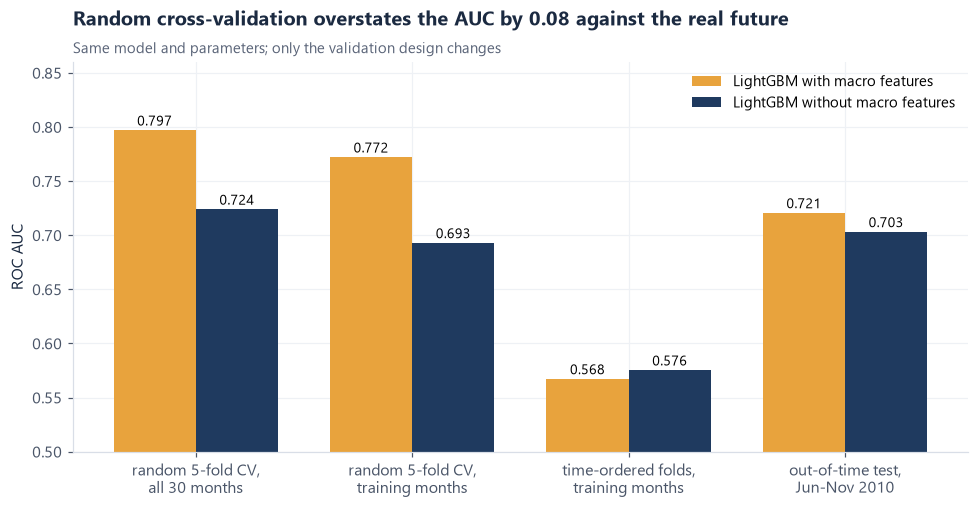

,with macro,without macro
"random 5-fold CV, all 30 months",0.7973,0.7242
"random 5-fold CV, training months",0.7724,0.6932
"time-ordered folds, training months",0.5675,0.5756
"out-of-time test, Jun-Nov 2010",0.7209,0.7034


In [3]:
BASE = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=4)
rcv = StratifiedKFold(5, shuffle=True, random_state=SEED)
trap = {}
for name, X in [("with macro", Xm), ("without macro", Xc)]:
    m = lgb.LGBMClassifier(**BASE)
    rand_all = select.cv_compare({"m": m}, X, y, rcv, scoring=("roc_auc",)).loc["m", "roc_auc_mean"]
    rand_tr = select.cv_compare({"m": m}, X[tr].reset_index(drop=True), y[tr], rcv, scoring=("roc_auc",)).loc["m", "roc_auc_mean"]
    time_tr = select.cv_compare({"m": m}, X[tr].reset_index(drop=True), y[tr], tcv, scoring=("roc_auc",)).loc["m", "roc_auc_mean"]
    oot = roc_auc_score(y[te], lgb.LGBMClassifier(**BASE).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1])
    trap[name] = {"random 5-fold CV, all 30 months": rand_all, "random 5-fold CV, training months": rand_tr,
                  "time-ordered folds, training months": time_tr, "out-of-time test, Jun-Nov 2010": oot}
trap = pd.DataFrame(trap)
fig, ax = plt.subplots(figsize=(10.5, 4.6))
xx = np.arange(len(trap))
for i, (c, colr) in enumerate([("with macro", PALETTE["amber"]), ("without macro", PALETTE["navy"])]):
    ax.bar(xx + (i - 0.5) * 0.38, trap[c], 0.38, color=colr, label=f"LightGBM {c} features")
    for j, v in enumerate(trap[c]):
        ax.text(xx[j] + (i - 0.5) * 0.38, v + 0.004, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(xx, [s.replace(", ", ",\n") for s in trap.index]); ax.set_ylim(0.5, max(0.86, trap.values.max() + 0.03)); ax.set_ylabel("ROC AUC")
ax.legend(loc="upper right")
gap = trap.loc["random 5-fold CV, all 30 months", "with macro"] - trap.loc["out-of-time test, Jun-Nov 2010", "with macro"]
headline(ax, f"Random cross-validation overstates the AUC by {gap:.2f} against the real future",
         "Same model and parameters; only the validation design changes")
_ = savefig(fig, "02-cv-vs-oot", FIG); plt.show()
trap

* **Random folds flatter the model.** Mixing all 30 months gives AUC 0.797 with macro inputs; the real future (June -
  November 2010) gives 0.721, 0.08 lower. Most of the gap comes from the macro inputs: they identify the month, and a
  random fold always contains other contacts from the same month. Without them the gap shrinks to 0.02 (0.724 vs 0.703).
* **Time-ordered folds are harsher than the test** (0.57-0.58). Each fold validates on a period whose macro values and
  base rate the model has never seen: spring 2009 right after the rate collapse, then the high-conversion regime of
  2009-10. The June-November 2010 test is easier, because by then training already holds a year of the low-rate
  regime.
* **So no single number is "the AUC".** Random CV says 0.80. The honest backtest says 0.57-0.72, depending on how new the
  regime is. The model card quotes the out-of-time test with its interval and says which kind of future it covers.

## 3. Candidates on time-ordered folds

A naive rule (the previous campaign's outcome), a regularised logistic regression (all preprocessing inside the
pipeline, `features.make_logistic`), HistGradientBoosting and an Optuna-tuned LightGBM, each with and without the
macro inputs. Tuning uses the same three time-ordered folds, never the test months.

Optuna: 20 trials, best time-ordered CV AUC 0.6073


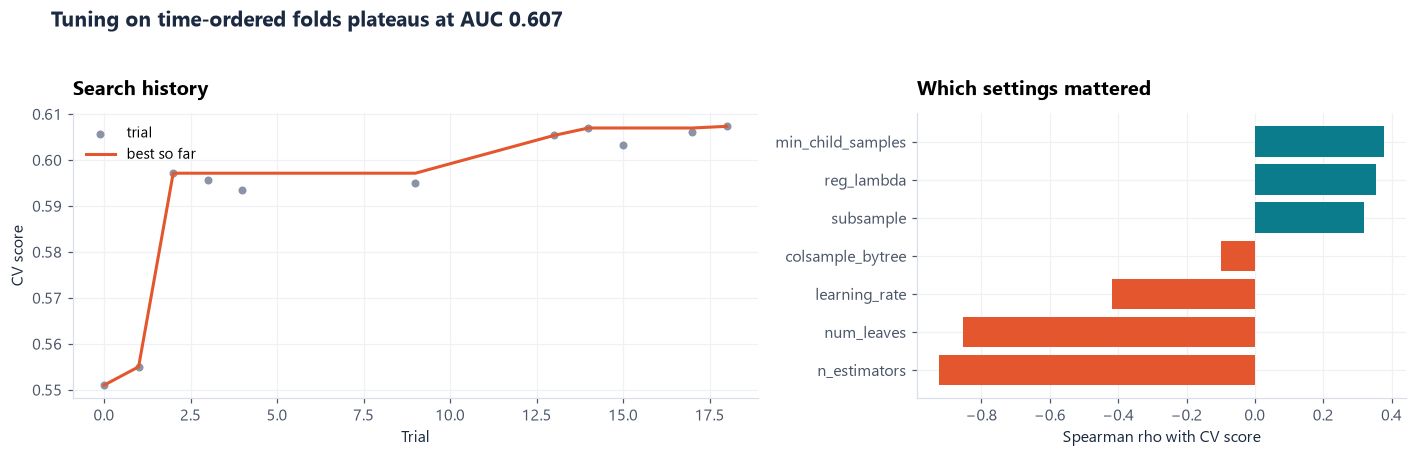

,roc_auc_mean,roc_auc_std,average_precision_mean,brier_score_mean,fold 1,fold 2,fold 3
model,,,,,,,
Rule: previous outcome,0.5853,0.0196,0.3982,0.2449,0.5860,0.5609,0.6089
"Logistic, no macro",0.6077,0.0334,0.4348,0.2322,0.5697,0.6024,0.6509
"Logistic, with macro",0.6108,0.0135,0.4382,0.2271,0.6225,0.5919,0.6179
"HistGB, no macro",0.5854,0.0344,0.4060,0.2318,0.5478,0.5773,0.6310
"HistGB, with macro",0.5984,0.0080,0.4191,0.2200,0.5892,0.5974,0.6087
"LightGBM tuned, no macro",0.5969,0.0320,0.4165,0.2290,0.5675,0.5818,0.6414
"LightGBM tuned, with macro",0.6073,0.0089,0.4231,0.2139,0.5957,0.6090,0.6173


In [4]:
rule = make_pipeline(ColumnTransformer([("p", OneHotEncoder(), ["poutcome"])]), LogisticRegression(max_iter=1000))
Xm_tr, Xc_tr = Xm[tr].reset_index(drop=True), Xc[tr].reset_index(drop=True)
best, study = select.tune_lgbm(Xm_tr, y[tr], tcv, n_trials=20, timeout=300, seed=SEED)  # trial-bound: reproducible on a busy machine
print(f"Optuna: {len(study.trials)} trials, best time-ordered CV AUC {study.best_value:.4f}")
fig = select.plot_optuna(study, title=f"Tuning on time-ordered folds plateaus at AUC {study.best_value:.3f}"); plt.show()
HGB = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0, random_state=SEED)
cands = {
    "Rule: previous outcome": (rule, Xc_tr),
    "Logistic, no macro": (F.make_logistic(macro=False), Xc_tr),
    "Logistic, with macro": (F.make_logistic(macro=True), Xm_tr),
    "HistGB, no macro": (HistGradientBoostingClassifier(**HGB), Xc_tr),
    "HistGB, with macro": (HistGradientBoostingClassifier(**HGB), Xm_tr),
    "LightGBM tuned, no macro": (lgb.LGBMClassifier(**best), Xc_tr),
    "LightGBM tuned, with macro": (lgb.LGBMClassifier(**best), Xm_tr),
}
cvt = pd.concat([select.cv_compare({n: m}, X_, y[tr], tcv) for n, (m, X_) in cands.items()])
fold_auc = pd.DataFrame({n: [roc_auc_score(y[tr][v_], m.fit(X_.iloc[t_], y[tr][t_]).predict_proba(X_.iloc[v_])[:, 1]) for t_, v_ in folds]
                         for n, (m, X_) in cands.items()}, index=[f"fold {i + 1}" for i in range(len(folds))]).T
cvt[["roc_auc_mean", "roc_auc_std", "average_precision_mean", "brier_score_mean"]].join(fold_auc)

* Every candidate is weak on the time-ordered folds (0.585-0.611 AUC). The previous-outcome rule alone reaches 0.585.
* Logistic regression with macro inputs has the best mean (0.611); LightGBM with macro inputs is close (0.607) with the
  smallest spread (+/- 0.009). Boosting does not beat a linear model here. The signal is a few strong, mostly additive
  effects: previous outcome, channel, age and the macro level.
* Tuning lifted LightGBM from 0.551 to 0.607 by shrinking it: fewer trees and fewer leaves correlate most with a better
  score. Under regime change, simpler models generalise better.

## 4. Out-of-time test: June - November 2010

In [5]:
Xm_te, Xc_te = Xm[te], Xc[te]
fitted = {n: m.fit(X_, y[tr]) for n, (m, X_) in cands.items()}
preds = {n: fitted[n].predict_proba(Xm_te if "with macro" in n else Xc_te)[:, 1] for n in cands}
yt = y[te]
mt = evaluate.metrics_table(yt, preds, n_boot=300, seed=SEED)
mt[["AUC", "AUC 95% CI", "PR AUC", "PR AUC 95% CI", "Brier", "Log loss"]]

,AUC,AUC 95% CI,PR AUC,PR AUC 95% CI,Brier,Log loss
model,,,,,,
Rule: previous outcome,0.6509,0.628 - 0.676,0.6381,0.618 - 0.661,0.2815,0.8455
"Logistic, no macro",0.7039,0.677 - 0.730,0.6800,0.651 - 0.711,0.2594,0.7544
"Logistic, with macro",0.7513,0.726 - 0.776,0.7232,0.693 - 0.756,0.2104,0.6115
"HistGB, no macro",0.7088,0.681 - 0.737,0.6910,0.661 - 0.722,0.2543,0.7409
"HistGB, with macro",0.7278,0.701 - 0.755,0.6877,0.659 - 0.719,0.2296,0.6516
"LightGBM tuned, no macro",0.7134,0.688 - 0.739,0.7000,0.670 - 0.732,0.2501,0.7297
"LightGBM tuned, with macro",0.7536,0.729 - 0.778,0.7123,0.681 - 0.742,0.2086,0.6062


In [6]:
pairs = {"LightGBM with macro - logistic with macro": ("LightGBM tuned, with macro", "Logistic, with macro"),
         "Logistic with macro - logistic no macro": ("Logistic, with macro", "Logistic, no macro"),
         "LightGBM with macro - LightGBM no macro": ("LightGBM tuned, with macro", "LightGBM tuned, no macro"),
         "Logistic no macro - rule": ("Logistic, no macro", "Rule: previous outcome"),
         "LightGBM no macro - logistic no macro": ("LightGBM tuned, no macro", "Logistic, no macro")}
paired = pd.DataFrame({k: evaluate.paired_auc_test(yt, preds[a], preds[b], n=1000, seed=SEED) for k, (a, b) in pairs.items()}).T
paired

,delta_auc,ci_low,ci_high,p_value_one_sided
LightGBM with macro - logistic with macro,0.0023,-0.0097,0.0144,0.3580
Logistic with macro - logistic no macro,0.0474,0.0325,0.0625,0.0000
LightGBM with macro - LightGBM no macro,0.0402,0.0226,0.0586,0.0000
Logistic no macro - rule,0.0530,0.0343,0.0715,0.0000
LightGBM no macro - logistic no macro,0.0095,-0.0000,0.0185,0.0260


* **Macro inputs lift every model on the test.** Logistic: 0.751 vs 0.704 (+0.047, paired 95% CI +0.033 to +0.063).
  LightGBM: 0.754 vs 0.713 (+0.040, CI +0.023 to +0.059).
* **Logistic and LightGBM tie.** With macro inputs: 0.751 vs 0.754, difference +0.002 (CI -0.010 to +0.014). Logistic has
  the higher PR AUC (0.723 vs 0.712), LightGBM the slightly lower Brier score (0.209 vs 0.210).
* **Both beat the previous-outcome rule** (0.651) by about 0.10.
* **Champion: logistic regression with macro inputs.** The evidence does not separate it from LightGBM, so simplicity
  decides: one coefficient per input, cheap to refit every month, and easy for a marketing team to sanity-check.
  LightGBM stays as the challenger.

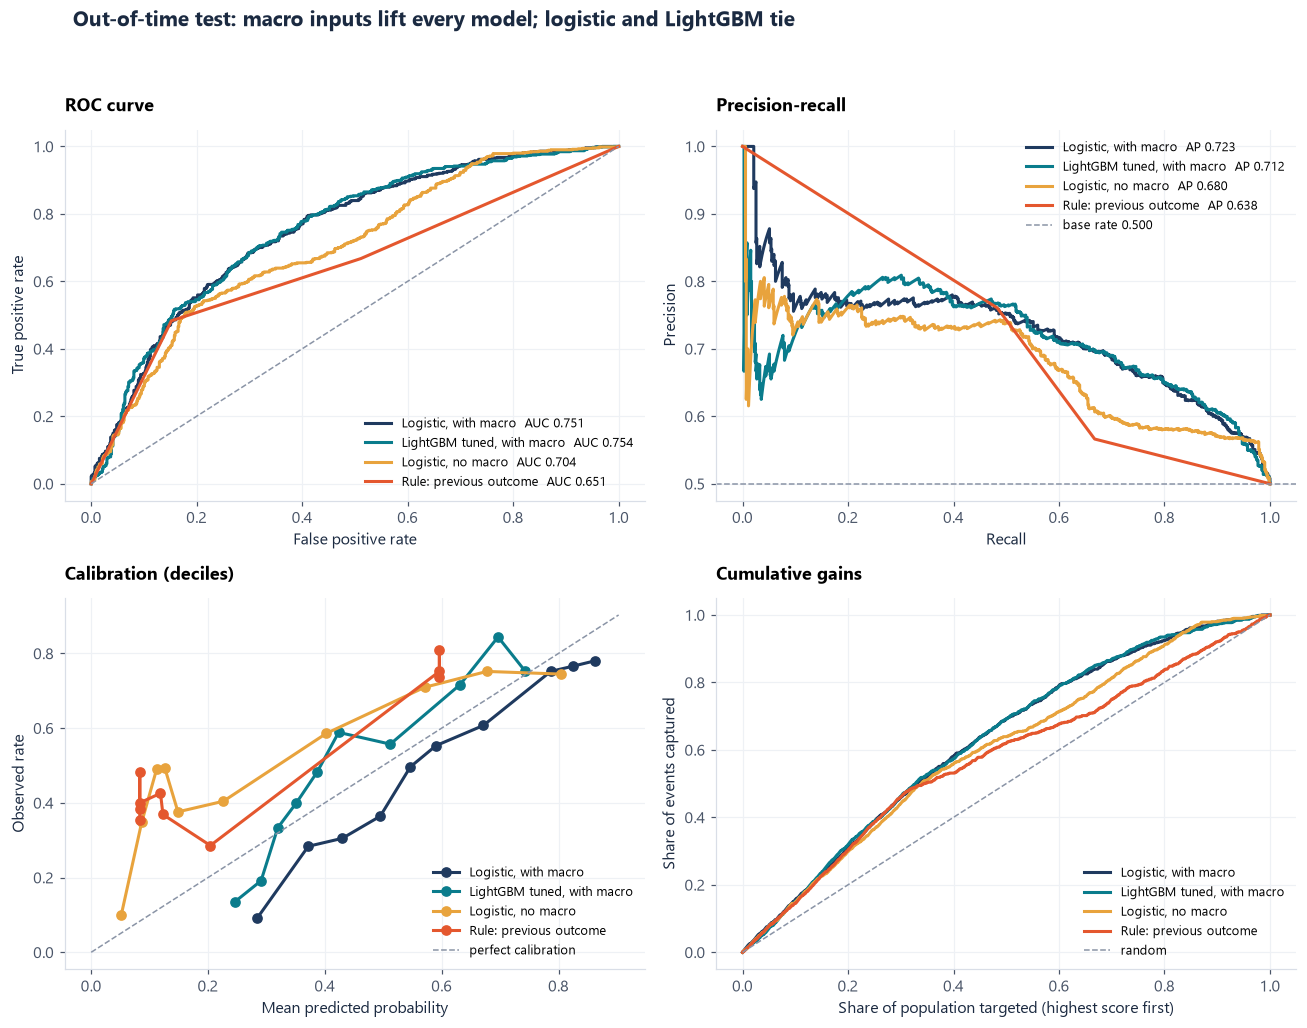

In [7]:
CHAMP, CHALL, NOMAC = "Logistic, with macro", "LightGBM tuned, with macro", "Logistic, no macro"
fig = evaluate.plot_binary_panel(yt, {k: preds[k] for k in [CHAMP, CHALL, NOMAC, "Rule: previous outcome"]},
                                 suptitle="Out-of-time test: macro inputs lift every model; logistic and LightGBM tie")
_ = savefig(fig, "02-test-panel", FIG); plt.show()

## 5. Calibration drift and a recalibration step

A model trained when 10% of contacts subscribed meets a period where half of them do. The contact policy in notebook 03
needs probabilities (expected value = p x margin - cost), so the level matters, not only the ranking. Each call month
from March 2009 is scored by a model refitted on every earlier month (walk-forward, monthly retrain), with and without
a rolling intercept shift estimated on the previous three months' outcomes (which the bank has by then). The same is
done for the champion and for its no-macro twin.

In [8]:
from sklearn.base import clone
wf = {"with macro": F.walk_forward(lambda: clone(fitted[CHAMP]), Xm, y, months, "2009-03-01"),
      "no macro": F.walk_forward(lambda: clone(fitted[NOMAC]), Xc, y, months, "2009-03-01")}
roll = {k: F.rolling_recalibration(v, y, months, window=3) for k, v in wf.items()}
scored = wf["with macro"].notna().to_numpy()
pre_test = scored & ~te
rows = []
for k in wf:
    for ver, s_ in (("monthly retrain, raw", wf[k]), ("monthly retrain + rolling shift", roll[k])):
        s_ = s_.to_numpy()
        for per_name, m_ in (("Mar 2009 - May 2010 (pre-test)", pre_test), ("Jun - Nov 2010 (test)", te)):
            rows.append({"inputs": k, "version": ver, "period": per_name, "pred / obs": s_[m_].mean() / y[m_].mean(),
                         "Brier": evaluate.binary_metrics(y[m_], s_[m_])["brier"], "AUC": roc_auc_score(y[m_], s_[m_])})
cal = pd.DataFrame(rows).set_index(["inputs", "version", "period"]).unstack("period")
fixed_cal = pd.DataFrame({n: {"pred / obs": preds[n].mean() / yt.mean(), "Brier": evaluate.binary_metrics(yt, preds[n])["brier"]} for n in (CHAMP, NOMAC)}).T
print("Fixed models (trained once on May 2008 - May 2010), test period:")
print(fixed_cal.round(3).to_string())
cal.round(3)

Fixed models (trained once on May 2008 - May 2010), test period:
                      pred / obs  Brier
Logistic, with macro      1.1730 0.2100
Logistic, no macro        0.6410 0.2590


pred / obs                                                Brier                                 \
period                                     Jun - Nov 2010 (test) Mar 2009 - May 2010 (pre-test) Jun - Nov 2010 (test) Mar 2009 - May 2010 (pre-test)   
inputs     version                                                                                                                                     
no macro   monthly retrain + rolling shift                1.0860                         1.4670                0.2260                         0.1780   
           monthly retrain, raw                           0.6580                         0.5180                0.2570                         0.1630   
with macro monthly retrain + rolling shift                1.1010                         1.7280                0.2100                         0.2960   
           monthly retrain, raw                           1.0960                         1.0470                0.2030                         0.1580   

                                                             AUC                                 
period                                     Jun - Nov 2010 (test) Mar 2009 - May 2010 (pre-test)  
inputs     version                                                                               
no macro   monthly retrain + rolling shift                0.7060                         0.5920  
           monthly retrain, raw                           0.7020                         0.6740  
with macro monthly retrain + rolling shift                0.7370                         0.5750  
           monthly retrain, raw                           0.7580                         0.6370

Champion, pre-test Brier: raw 0.1577 vs rolling shift 0.2960 -> policy uses raw monthly-retrain scores


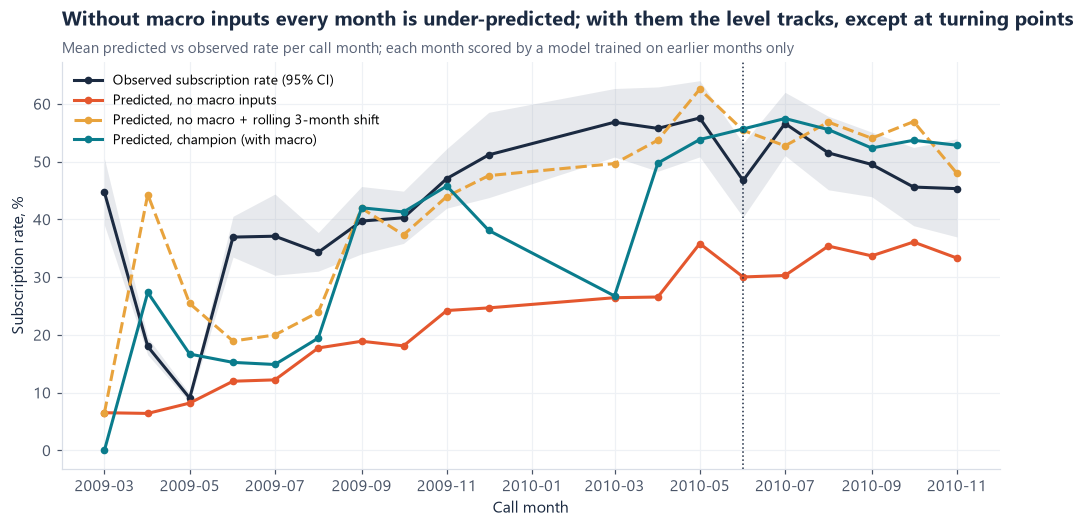

In [9]:
# Which version feeds the policy? Decide on the pre-test walk-forward months only (the test months stay untouched).
b_raw = cal.loc[("with macro", "monthly retrain, raw"), ("Brier", "Mar 2009 - May 2010 (pre-test)")]
b_roll = cal.loc[("with macro", "monthly retrain + rolling shift"), ("Brier", "Mar 2009 - May 2010 (pre-test)")]
RECAL = bool(b_roll < b_raw)
print(f"Champion, pre-test Brier: raw {b_raw:.4f} vs rolling shift {b_roll:.4f} -> policy uses {'the rolling shift' if RECAL else 'raw monthly-retrain scores'}")
mm = pd.DataFrame({"m": months, "y": y, "nomac": wf["no macro"], "nomac_roll": roll["no macro"], "mac": wf["with macro"]})
mm = mm[scored].groupby("m").agg(n=("y", "size"), observed=("y", "mean"), nomac=("nomac", "mean"), nomac_roll=("nomac_roll", "mean"), mac=("mac", "mean"))
lo, hi = eda.wilson(mm["observed"] * mm["n"], mm["n"])
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(mm.index, lo * 100, hi * 100, color=PALETTE["grey"], alpha=0.2, lw=0)
ax.plot(mm.index, mm["observed"] * 100, color=PALETTE["ink"], marker="o", ms=4, label="Observed subscription rate (95% CI)")
ax.plot(mm.index, mm["nomac"] * 100, color=PALETTE["coral"], marker="o", ms=4, label="Predicted, no macro inputs")
ax.plot(mm.index, mm["nomac_roll"] * 100, color=PALETTE["amber"], marker="o", ms=4, ls="--", label="Predicted, no macro + rolling 3-month shift")
ax.plot(mm.index, mm["mac"] * 100, color=PALETTE["teal"], marker="o", ms=4, label="Predicted, champion (with macro)")
ax.axvline(F.TEST_START, color=PALETTE["ink"], lw=1, ls=":")
ax.set(ylabel="Subscription rate, %", xlabel="Call month"); ax.legend(loc="upper left", fontsize=9)
headline(ax, "Without macro inputs every month is under-predicted; with them the level tracks, except at turning points",
         "Mean predicted vs observed rate per call month; each month scored by a model trained on earlier months only")
_ = savefig(fig, "02-calibration-drift", FIG); plt.show()
p_policy = (roll if RECAL else wf)["with macro"].to_numpy()

* **Fixed models on the test:** the no-macro logistic predicts 0.64x the observed rate (a third too low); the macro
  champion predicts 1.17x (a sixth too high).
* **Monthly retraining fixes the macro model, not the no-macro one.** Walk-forward, the champion runs at 1.05x the
  observed rate before the test and 1.10x during it; the no-macro model stays at 0.52-0.66x.
* **A rolling intercept shift rescues the no-macro model on the test (0.66x to 1.09x) but overshoots before it (1.47x).**
  The base rate swings month to month (45% in March 2009, 9% in May), and a three-month window always lags. On the
  champion the shift makes things worse (pre-test Brier 0.296 vs 0.158), so the policy uses the raw monthly-retrain
  scores. That choice was made on pre-test months only.
* **The macro model misses at turning points.** In March 2009, just after the rate collapse, it predicts close to 0%
  against 45% observed. In March 2010, after a two-month gap in calling, it predicts 27% against 57%. Employment
  variation was -1.8 in both springs, while conversion was 9-45% in 2009 and 56-58% in 2010, so the model cannot tell
  them apart. A month after a gap or a macro shock should be treated as a new regime: score it, but recalibrate once
  the first outcomes arrive.

## 6. Segment performance (test period)

In [10]:
seg = pd.DataFrame({"y": yt, "p": preds[CHAMP], "job": df.loc[te, "job"].values, "channel": df.loc[te, "contact"].values,
                    "prior": df.loc[te, "poutcome"].values,
                    "age band": pd.cut(df.loc[te, "age"], [0, 30, 45, 60, 120], right=False, labels=["Under 30", "30-44", "45-59", "60+"]).astype(str).values})
segt = pd.concat({g: evaluate.segment_performance(seg, g, "y", "p", min_n=60) for g in ["age band", "channel", "prior", "job"]}, names=["segment", "level"])
segt

rows  base_rate  mean_pred  calibration_ratio    auc
segment  level                                                            
age band 30-44         592     0.4764     0.5633             1.1826 0.7700
         45-59         239     0.5314     0.5718             1.0761 0.7827
         60+           225     0.5644     0.6324             1.1204 0.6969
         Under 30      352     0.4773     0.6053             1.2683 0.7397
channel  cellular     1124     0.5747     0.6370             1.1083 0.6901
         telephone     284     0.2042     0.3858             1.8893 0.7350
prior    failure       383     0.3394     0.4538             1.3370 0.5974
         nonexistent   578     0.4048     0.4990             1.2325 0.7178
         success       447     0.7606     0.8128             1.0686 0.5343
job      admin.        433     0.5035     0.5848             1.1615 0.7440
         blue-collar    91     0.4396     0.4895             1.1136 0.7975
         management     85     0.5412     0.5841             1.0793 0.8501
         retired       179     0.5531     0.6464             1.1687 0.7366
         services       87     0.4138     0.4704             1.1367 0.8644
         student       145     0.4690     0.6750             1.4394 0.7968
         technician    225     0.5467     0.5918             1.0826 0.6883

Discrimination holds across age bands (AUC 0.70-0.78) and jobs (0.69-0.86, small groups). Read the calibration ratios
against the overall 1.17 of the fixed model. Two segments stand out: landline contacts are over-predicted almost 2x
(observed 20%, predicted 39%), and students by 44% (47% vs 68%), the segment whose lift faded over time (notebook 01).
Among previous successes the model barely ranks (AUC 0.53). They convert at 76% and the model treats them as uniformly
hot, which is the right call for a call list.

## 7. What drives the score

Three views: the champion's coefficients, permutation importance on the test months (with the five macro inputs
shuffled together, because they are near-copies and shuffling one alone hides the group), and SHAP on the LightGBM
challenger as an independent check.

In [11]:
champ = fitted[CHAMP]
coef = pd.Series(champ[-1].coef_[0], index=champ[:-1].get_feature_names_out()).rename(lambda c: c.split("__", 1)[1])
coef_t = coef.to_frame("coefficient (per sd or vs other levels)").assign(odds_ratio=np.exp(coef)).reindex(coef.abs().sort_values(ascending=False).index)
GROUPS = {"macro (all 5, shuffled together)": F.MACRO, "contact channel": ["contact"], "previous campaign (outcome, count, days)": ["poutcome", "previous", "contacted_before", "days_since_prior"],
          "age": ["age"], "job": ["job"], "credit default status": ["default"], "weekday": ["day_of_week"], "education": ["education"],
          "marital status": ["marital"], "housing / personal loan": ["housing", "loan"]}
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(yt, champ.predict_proba(Xm_te)[:, 1])
gperm = {}
for g, cols in GROUPS.items():
    drops = []
    for _ in range(10):
        Xp = Xm_te.copy()
        ix = rng.permutation(len(Xp))
        for c in cols:                                  # one row permutation for the whole group, dtype kept per column
            Xp[c] = Xm_te[c].iloc[ix].set_axis(Xp.index)
        drops.append(base_auc - roc_auc_score(yt, champ.predict_proba(Xp)[:, 1]))
    gperm[g] = {"test AUC drop": np.mean(drops), "sd": np.std(drops)}
gperm = pd.DataFrame(gperm).T.sort_values("test AUC drop", ascending=False)
print("Champion coefficients, largest first:")
print(coef_t.head(10).round(3).to_string())
gperm

Champion coefficients, largest first:
                   coefficient (per sd or vs other levels)  odds_ratio
emp.var.rate                                       -1.0620      0.3460
contact_telephone                                  -0.7790      0.4590
poutcome_failure                                   -0.6660      0.5140
cons.price.idx                                      0.6220      1.8630
default_unknown                                    -0.5070      0.6020
job_student                                         0.3490      1.4170
day_of_week_mon                                    -0.3350      0.7150
marital_divorced                                   -0.3200      0.7260
nr.employed                                        -0.3010      0.7400
job_retired                                         0.2940      1.3410


,test AUC drop,sd
"previous campaign (outcome, count, days)",0.1804,0.0059
contact channel,0.0571,0.0062
weekday,0.0079,0.0025
age,0.0009,0.0006
credit default status,0.0008,0.0004
"macro (all 5, shuffled together)",0.0008,0.0021
education,-0.0000,0.0015
housing / personal loan,-0.0003,0.0005
job,-0.0024,0.0029
marital status,-0.0037,0.0013


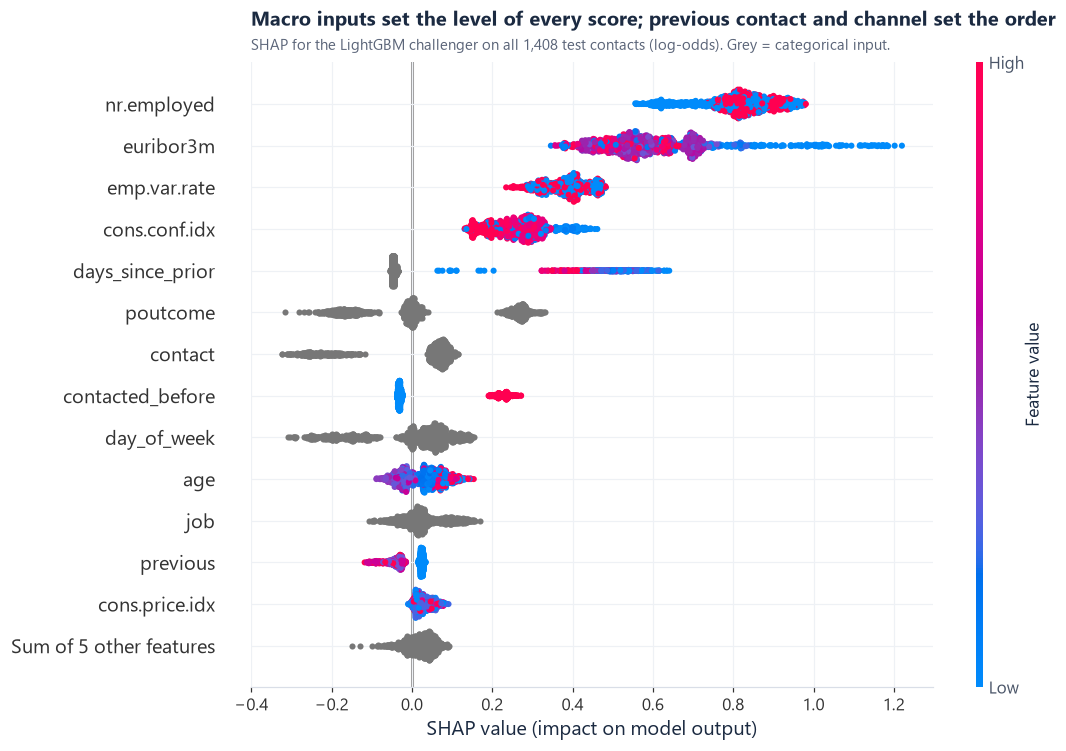

,SHAP share (challenger),test AUC drop (champion)
"macro (all 5, shuffled together)",0.7247,0.0008
"previous campaign (outcome, count, days)",0.1641,0.1804
contact channel,0.0352,0.0571
weekday,0.0274,0.0079
age,0.0161,0.0009
job,0.0143,-0.0024
education,0.0059,-0.0000
marital status,0.0044,-0.0037
housing / personal loan,0.0039,-0.0003
credit default status,0.0039,0.0008


In [12]:
e = explain.shap_explanation(fitted[CHALL], Xm_te, sample=3000, seed=SEED)
fig = explain.plot_shap_beeswarm(e, max_display=14, title="Macro inputs set the level of every score; previous contact and channel set the order",
                                 subtitle="SHAP for the LightGBM challenger on all 1,408 test contacts (log-odds). Grey = categorical input.")
_ = savefig(fig, "02-shap-beeswarm", FIG); plt.show()
imp = explain.shap_importance(e)
grp_shap = {g: imp.loc[[c for c in cols if c in imp.index], "share"].sum() for g, cols in GROUPS.items()}
pd.DataFrame({"SHAP share (challenger)": pd.Series(grp_shap), "test AUC drop (champion)": gperm["test AUC drop"]}).sort_values("SHAP share (challenger)", ascending=False)

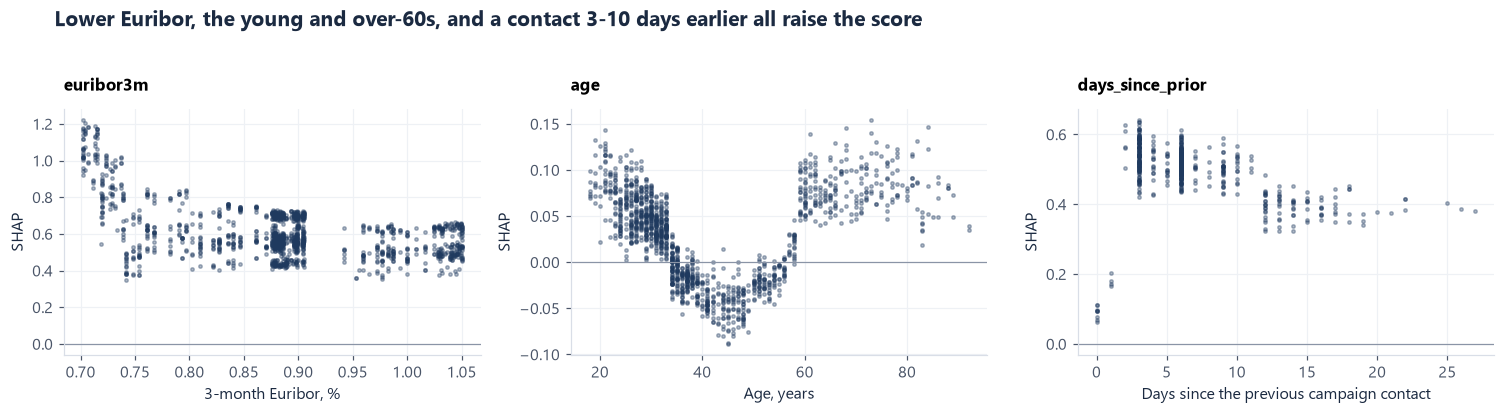

In [13]:
fig = explain.plot_shap_dependence(e, ["euribor3m", "age", "days_since_prior"], ncols=3, title="Lower Euribor, the young and over-60s, and a contact 3-10 days earlier all raise the score")
for ax, xl in zip(fig.axes[:3], ["3-month Euribor, %", "Age, years", "Days since the previous campaign contact"]):
    ax.set_xlabel(xl)
plt.show()

* **Coefficients (champion).** The employment variation rate has the largest effect (-1.06 log-odds per standard
  deviation). Then come landline contact (odds x0.46), a failed previous campaign (x0.51), the consumer price index
  (+0.62 per sd), unknown credit-default status (x0.60), students (x1.42) and Monday calls (x0.72).
* **Two importance measures disagree, and both are right.** SHAP puts 72% of the challenger's explanation on the macro
  inputs, yet shuffling those inputs on the test months moves the champion's AUC by 0.001. SHAP measures how far each
  input moves a score from the training average, and in 2010 every score sits far above the 2008 average because of
  the macro level. Permutation measures each input's contribution to the ranking within the test window, where the
  macro level is nearly constant. For whom to call within a month, what matters is previous-campaign history (AUC drop
  0.18 when shuffled), contact channel (0.06) and weekday (0.01).
* **Then why do macro inputs lift test AUC by 0.05?** Because of what they do in training. Without them, the client
  coefficients absorb the regime: previous successes and mobile contacts were rare in 2008 and common in 2010, so their
  effects get confounded with the base rate. With the macro inputs carrying the level, the client effects are
  estimated within period, and the ranking transfers.
* **Shapes:** the score rises as Euribor falls below 0.75%, is U-shaped in age (lowest at 40-50), and peaks when the
  previous contact was 3-10 days earlier.

## 8. Drift between training and test

In [14]:
psi = eda.stability(Xm[tr], Xm[te], list(Xm.columns))
sc_tr, sc_te = champ.predict_proba(Xm[tr])[:, 1], preds[CHAMP]
print(f"Champion score PSI, training period vs test period: {eda.psi(sc_tr, sc_te):.2f}")
psi.head(12)

Champion score PSI, training period vs test period: 11.53


,psi,status
feature,,
nr.employed,13.7838,shifted
cons.conf.idx,13.5729,shifted
euribor3m,12.4902,shifted
emp.var.rate,9.6101,shifted
cons.price.idx,9.1129,shifted
poutcome,1.3057,shifted
previous,1.1017,shifted
contacted_before,1.0292,shifted
job,0.5232,shifted


Every macro input has a PSI of 9-14, as expected: the test months sit in a different economy. The client mix has
shifted too: previous outcome (1.31), number of previous contacts (1.10), job (0.52), credit-default status (0.52)
and age (0.28). The 2010 list is mostly people the bank had called before, and the score's PSI is 11.5. None of this is
a reason to stop scoring, but each kind of shift should trigger a different review. Macro PSI means "check the
calibration"; client-mix PSI means "the list source changed: check the ranking still holds".

## 9. Decision

* **Champion: logistic regression with macro inputs**, retrained monthly on all earlier months, with no extra intercept
  shift. Out-of-time AUC 0.751 (95% CI 0.726-0.776), against 0.651 for the previous-outcome rule. Tuned LightGBM (0.754)
  is the challenger; the two are tied.
* **Always validate out of time.** Random CV reports 0.80 for a model whose out-of-time AUC is 0.72.
* **Use the score to rank within a month first; trust the probabilities after a calibration check.** The level tracks
  most months but fails at regime turns, so the first month after a gap gets recalibrated on its first outcomes.
* Notebook 03 turns these walk-forward scores into a contact policy.

## 10. Limitations

* **Selection, not just economics.** In 2009-10 the bank called far fewer clients, and more of them had been contacted
  before. Part of the rise in conversion is who was called, not only the interest-rate backdrop. The data cannot
  separate the two; a randomised holdout can (notebook 03).
* **A small, unusual test window.** 1,408 contacts at a 50% base rate. AUC intervals are about +/- 0.03 wide, and the
  test period's economics (rates near zero) are not the 2008 world.
* **No client identifier.** The same person can appear in several campaigns, so client-level leakage across the split
  cannot be ruled out.
* **Propensity, not uplift.** The model predicts who subscribes when called, not who subscribes because they were
  called. Clients who would have opened a deposit anyway look like the best targets. The holdout design in notebook
  03 is the way to measure the causal effect.

## 11. What I would do next

* Fit an uplift model on a randomised call/no-call test so the list targets persuadable clients, not sure things.
* Add product holdings and balance data (not in the public file) to separate who can afford a deposit from who is
  reachable.
* Monitor monthly: PSI of each input, predicted vs observed rate, and the AUC on the latest closed month, with
  recalibration every month and a refit when AUC drops below the fold-1 level.

In [15]:
report.update_metrics(METRICS, "02_propensity_model", {
    "train_rows": int(tr.sum()), "test_rows": int(te.sum()), "train_rate": float(y[tr].mean()), "test_rate": float(yt.mean()),
    "validation_trap": trap.to_dict(), "cv_time_auc": cvt["roc_auc_mean"].to_dict(),
    "test": {k: {"auc": float(r["AUC"]), "auc_ci": r["AUC 95% CI"], "pr_auc": float(r["PR AUC"]), "brier": float(r["Brier"])} for k, r in mt.iterrows()},
    "paired_tests": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in paired.iterrows()},
    "champion": CHAMP, "challenger": CHALL, "challenger_params": best, "policy_recalibrate": RECAL,
    "calibration_walk_forward": {f"{i[0]} | {i[1]}": {f"{m} | {per}": float(v) for (m, per), v in r.items()} for i, r in cal.iterrows()},
    "grouped_permutation": gperm["test AUC drop"].to_dict(),
    "score_psi_train_test": float(eda.psi(sc_tr, sc_te)),
})
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 127 s
